- Github repository: https://github.com/Simen03/simen03-ind320-app 
- Streamlit app: https://simen03-ind320-app-hkg3slagiyz8dtmwljxdtd.streamlit.app/
- Link to video: 

### AI usage

During the assignment I used Claude to help me break down the task to smaller tasks and to describe what I needed to do in some of the casses that I didn't understand how to solve on my own

I used the github copilot in VS code if I had some trouble with the code or something didn't work. I also used it to import the different libaries i needed. 

### Log


### Imports

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Importing the data

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

from modules.NVE_API import fetch_reservoirs, areas, select_area, pivot_filling, Values

df = fetch_reservoirs()
print(df["region_type"].unique())                      # which region types exist?
print(df.groupby("region_type")["region_number"].unique())


['EL' 'NO' 'VASS']
region_type
EL      [4, 1, 3, 5, 2]
NO                  [0]
VASS          [2, 3, 1]
Name: region_number, dtype: object


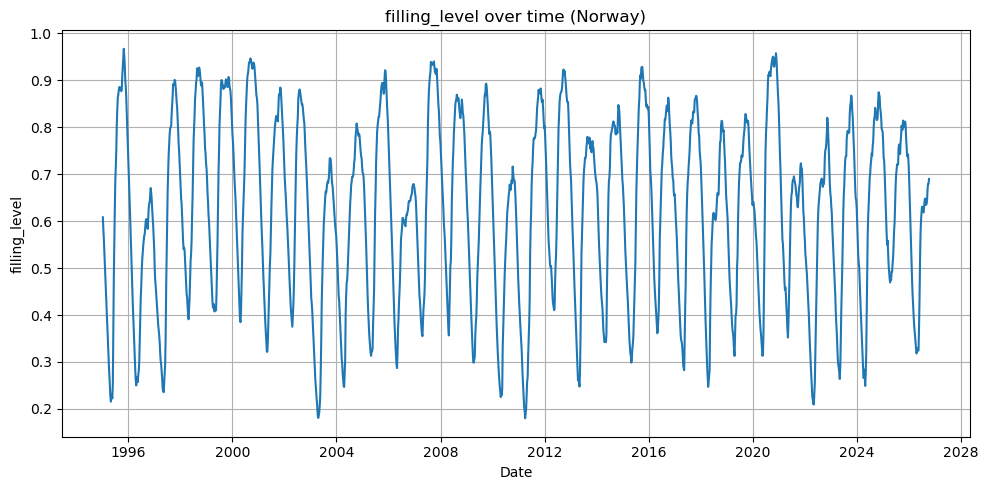

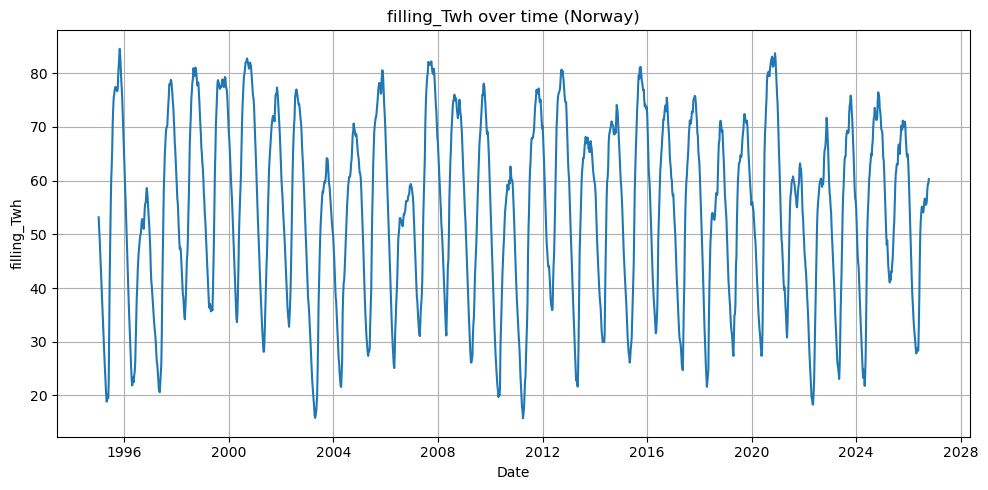

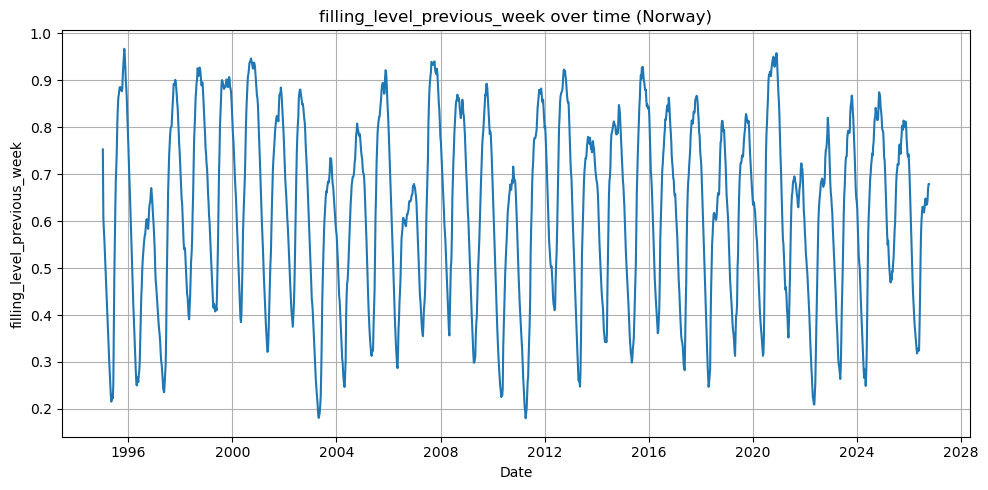

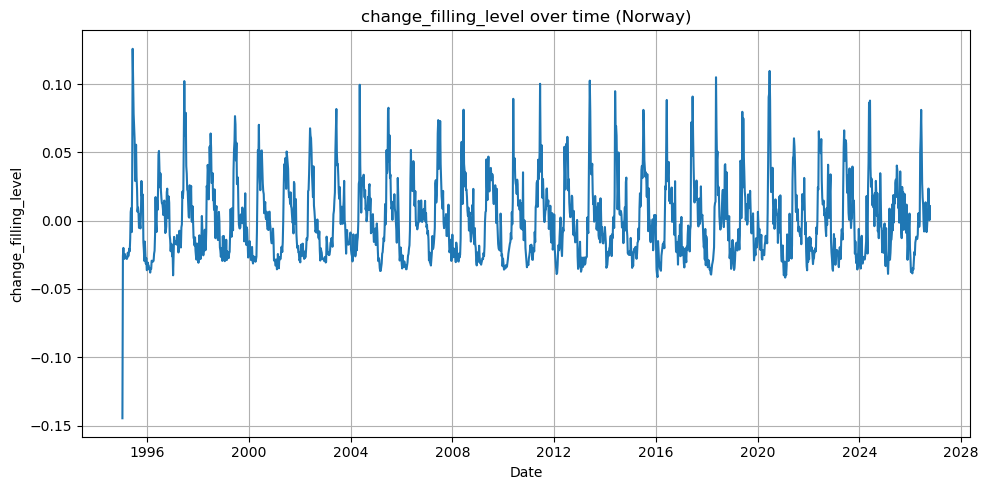

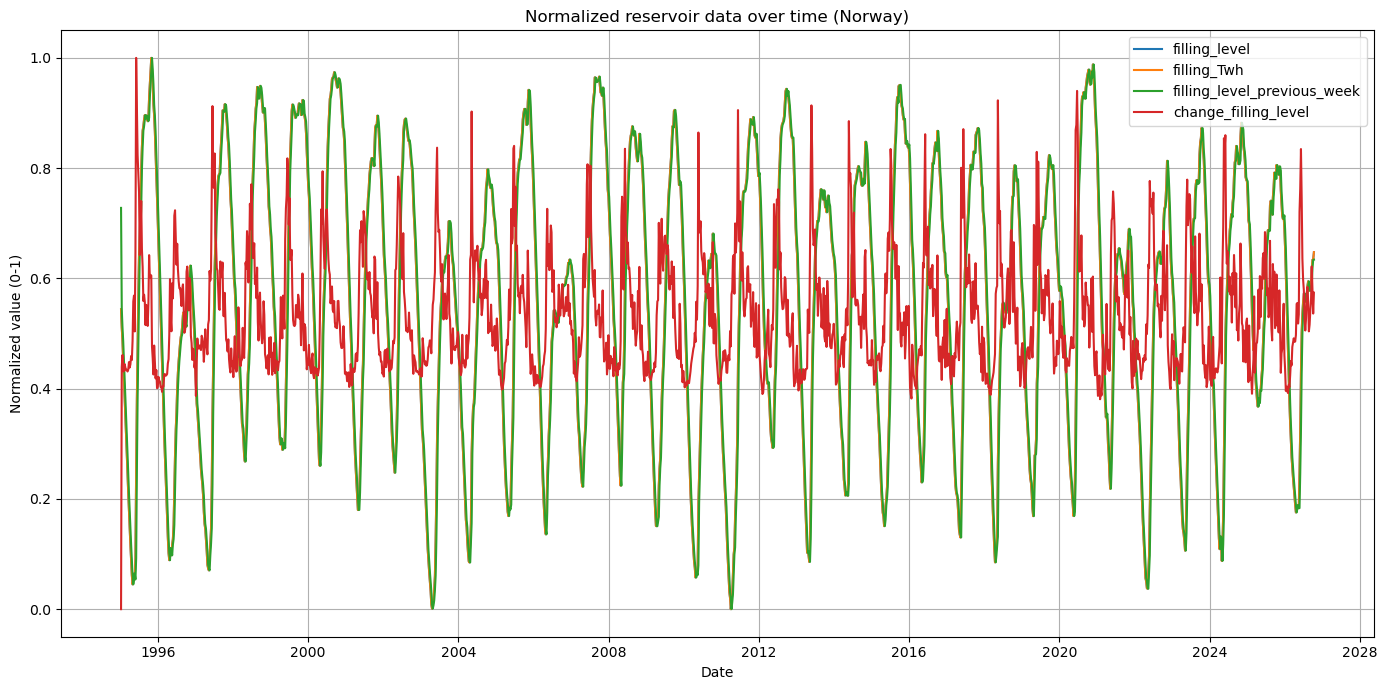

In [5]:

plot_cols = ['filling_level', 'filling_Twh',
             'filling_level_previous_week', 'change_filling_level']  # same as part 1, no capacity

no_df = select_area(df, "NO", 0)[plot_cols]

# each column separately
for col in no_df.columns:
    plt.figure(figsize=(10, 5))
    plt.plot(no_df.index, no_df[col])
    plt.title(f"{col} over time (Norway)")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# all together, normalized 0-1
norm = ((no_df - no_df.min()) / (no_df.max() - no_df.min())).fillna(0)

plt.figure(figsize=(14, 7))
for col in norm.columns:
    plt.plot(norm.index, norm[col], label=col)
plt.title("Normalized reservoir data over time (Norway)")
plt.xlabel("Date")
plt.ylabel("Normalized value (0-1)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()